In [451]:
import pandas as pd
import requests
import numpy as np

from PIL import Image
import io
from IPython.display import display,clear_output,Image
import ipywidgets as widgets
import sounddevice as sd
import soundfile as sf

In [378]:
#use earpod for sound output
sd._terminate(); sd._initialize()
print(sd.query_devices())

< 0 EarPods, Core Audio (0 in, 2 out)
> 1 EarPods Microphone, Core Audio (1 in, 0 out)
  2 MacBook Pro Microphone, Core Audio (1 in, 0 out)
  3 MacBook Pro Speakers, Core Audio (0 in, 2 out)
  4 Microsoft Teams Audio, Core Audio (1 in, 1 out)
  5 ZoomAudioDevice, Core Audio (2 in, 2 out)


In [379]:
game_df = pd.read_csv('data/sound_img_list.csv')
display(game_df)

,name,location,img_url
0,bear,Sound/bear.mp3,https://commons.wikimedia.org/wiki/Special:Fil...
1,cat,Sound/cat.mp3,https://commons.wikimedia.org/wiki/Special:Fil...
2,chicken,Sound/chicken.mp3,https://commons.wikimedia.org/wiki/Special:Fil...
3,chicks,Sound/chicks.mp3,https://commons.wikimedia.org/wiki/Special:Fil...
4,cow,Sound/cow.mp3,https://commons.wikimedia.org/wiki/Special:Fil...
5,dog,Sound/dog.mp3,https://commons.wikimedia.org/wiki/Special:Fil...
6,donkey,Sound/donkey.mp3,https://commons.wikimedia.org/wiki/Special:Fil...
7,duck,Sound/duck.mp3,https://commons.wikimedia.org/wiki/Special:Fil...
8,elephant,Sound/elephant.mp3,https://commons.wikimedia.org/wiki/Special:Fil...
9,frog,Sound/frog.mp3,https://commons.wikimedia.org/wiki/Special:Fil...


In [380]:
# def play_sound(i):
#     path = game_df.location.sample().iloc[i]
#     data,sr = sf.read(path)
#     sd.play(data,sr)

# def stop_sound():
#     sd.stop()

In [381]:
# def play_sound_button(i):
#     play_button=widgets.Button(
#             value = False,
#             description ='play animal sound',
#             disabled = False,
#             button_style='info',
            
#     )
#     play_button.on_click(lambda b:play_sound(i))
#     display(play_button)


In [382]:
play_sound_button(0)

Button(button_style='info', description='play animal sound', style=ButtonStyle())

In [383]:
def stop_sound_button(i):
    stop_button=widgets.Button(
        description ='stop animal sound',
         disabled = False,
         button_style='info',
    )
    stop_button.on_click(lambda b:sd.stop())
    display(stop_button)

In [384]:
stop_sound_button(0)

Button(button_style='info', description='stop animal sound', style=ButtonStyle())

In [450]:
ui_imag_df = pd.read_csv('data/UI_img_list.csv')
display(ui_imag_df)

,name,location
0,farm,Image/farm_bkg.png
1,Luma,Image/Luma.png
2,Ray,Image/Ray.png


In [385]:
# The play button plays that stored animal’s sound.
# The options are built from that stored animal plus two different wrong ones, shuffled.
# The checker compares the clicked name to that stored name, not to a function call.

In [396]:
def sound_selection():
    choices = game_df.drop_duplicates('name').sample(5)
    correct_answer = choices.sample().iloc[0]

    sound_selection_buttons = widgets.ToggleButtons(
        options=list(choices['name']),
        value=None,
        description='Choose the animal that makes the sound:',
        button_style=''
    )

    def play_sound(b):
        data, sr = sf.read(correct_answer['location'])
        sd.play(data, sr)

    play_button = widgets.Button(
        description='play animal sound'
        , button_style='info'
    )
    play_button.on_click(play_sound)

    stop_sound_button = widgets.Button(
        description='stop animal sound',
        button_style='info'
    )
    stop_sound_button.on_click(lambda b: sd.stop())

    output = widgets.Output()

    @output.capture(clear_output =True)
    def button_clicker(change):
        if change.new == correct_answer['name']:
            print('correct!')
        else:
            print('wrong')

    sound_selection_buttons.observe(button_clicker, names='value')
    display(widgets.VBox([play_button, stop_sound_button,sound_selection_buttons, output]))

sound_selection()

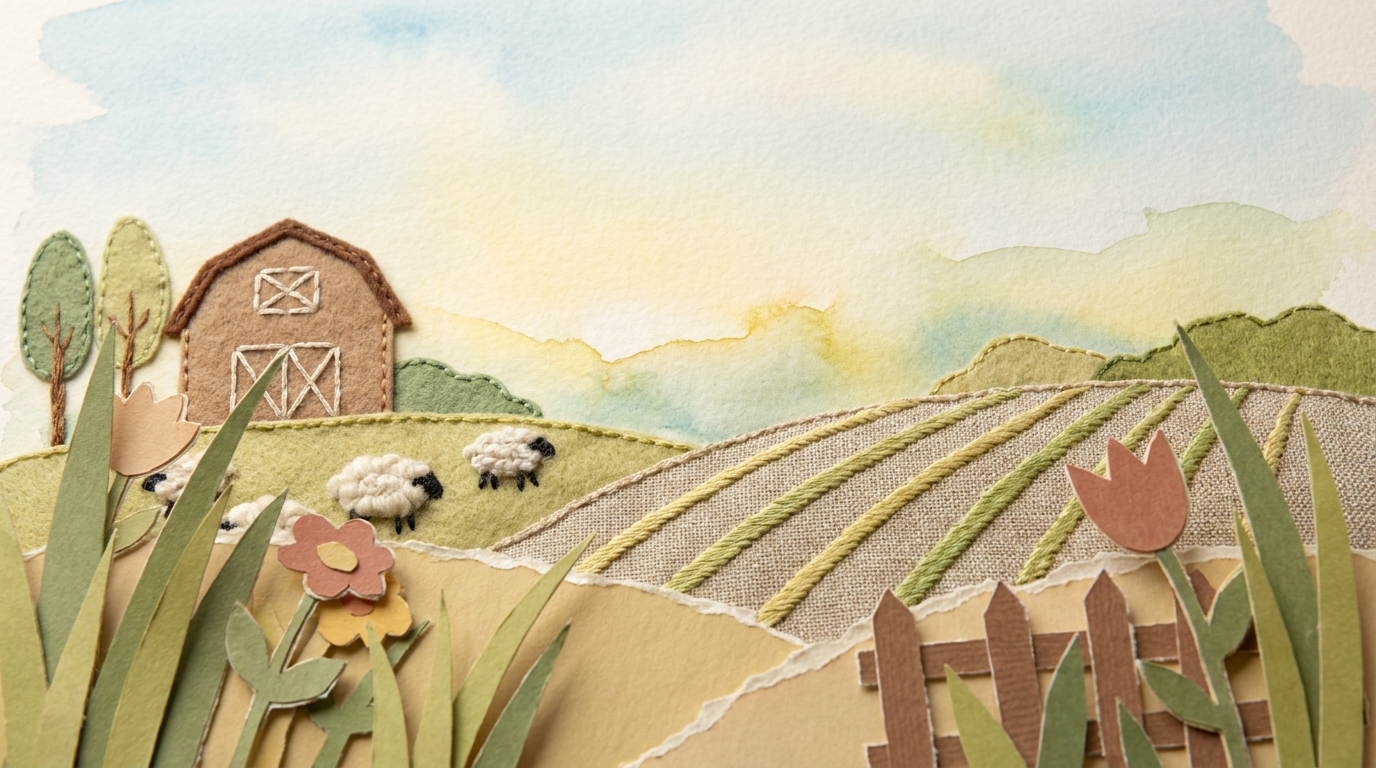

Button(button_style='info', description='Start Game!', style=ButtonStyle())

Output()

Button(button_style='primary', description='Back to Menu', layout=Layout(display='none'), style=ButtonStyle())

In [453]:
def menu_state():
    start_game_button = widgets.Button(
        description='Start Game!',
        button_style='info'
    )
    fram_bkg_path = ui_imag_df.location.iloc[0]
    display(Image(filename=fram_bkg_path,width=300))
    
    
    back_to_menu_btn = widgets.Button(
        description='Back to Menu',
        button_style='primary'
    )
    back_to_menu_btn.layout.display = 'none'
    output = widgets.Output()
    @output.capture(clear_output =True)
   
    def start_game(b):
        start_game_button.layout.display = 'none'
        sound_selection()
        back_to_menu_btn.layout.display = ''

    def restart_game(b):
        
        output.clear_output()
        start_game_button.layout.display = ''
        back_to_menu_btn.layout.display = 'none'

    back_to_menu_btn.on_click(restart_game)
    start_game_button.on_click(start_game)
    display(start_game_button,output,back_to_menu_btn)

menu_state()